In [8]:
import pandas as pd
import sys
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [2]:
# Find the hotel dataset
project_path = Path(r"E:\AI-Bootcamp\Module_05")

dataset_files = list(
    project_path.rglob("hotel_support_tickets.csv")
)

if not dataset_files:
    raise FileNotFoundError("Hotel dataset was not found.")

dataset_path = dataset_files[0]

# Load dataset
df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset location:", dataset_path)
print("Total tickets:", len(df))

display(df.head())

Dataset loaded successfully!
Dataset location: E:\AI-Bootcamp\Module_05\a\dataset\hotel_support_tickets.csv
Total tickets: 100


,id,ticket,expected_category,split,required_terms
0,H001,I have not received my room booking confirmation.,Booking_Issue,development,booking
1,H002,My online room reservation is missing.,Booking_Issue,development,booking
2,H003,I booked a double room but received a single r...,Booking_Issue,development,booking
3,H004,The booking website shows an incorrect reserva...,Booking_Issue,development,booking
4,H005,I cannot find my hotel reservation number.,Booking_Issue,development,booking


In [3]:
# Select only evaluation tickets
eval_df = df[df["split"] == "eval"].copy()

print("Total evaluation tickets:", len(eval_df))

display(
    eval_df[["id", "ticket", "expected_category"]]
)

Total evaluation tickets: 20


,id,ticket,expected_category
8,H009,The hotel website is not accepting my room boo...,Booking_Issue
9,H010,My reservation details are incorrect.,Booking_Issue
18,H019,Please confirm my room cancellation.,Cancellation_Issue
19,H020,I need to know the cancellation policy.,Cancellation_Issue
28,H029,My room access card is not working.,Checkin_Checkout
29,H030,The reception staff is not helping with check-in.,Checkin_Checkout
38,H039,My room has not received daily cleaning.,Room_Cleanliness
39,H040,The bathroom floor is dirty.,Room_Cleanliness
48,H049,There are no clean towels in my room.,Room_Amenities
49,H050,The hair dryer is not available.,Room_Amenities


In [4]:
# Add the folder containing hotel_service.py
service_path = r"E:\AI-Bootcamp\Module_05\a"

if service_path not in sys.path:
    sys.path.insert(0, service_path)

from hotel_service import analyze_ticket

# Predict categories
eval_df["predicted_category"] = eval_df["ticket"].apply(
    lambda ticket: analyze_ticket(ticket).category
)

display(
    eval_df[
        ["id", "ticket", "expected_category", "predicted_category"]
    ]
)

,id,ticket,expected_category,predicted_category
8,H009,The hotel website is not accepting my room boo...,Booking_Issue,Booking_Issue
9,H010,My reservation details are incorrect.,Booking_Issue,Booking_Issue
18,H019,Please confirm my room cancellation.,Cancellation_Issue,Cancellation_Issue
19,H020,I need to know the cancellation policy.,Cancellation_Issue,Cancellation_Issue
28,H029,My room access card is not working.,Checkin_Checkout,Room_Amenities
29,H030,The reception staff is not helping with check-in.,Checkin_Checkout,Checkin_Checkout
38,H039,My room has not received daily cleaning.,Room_Cleanliness,Room_Cleanliness
39,H040,The bathroom floor is dirty.,Room_Cleanliness,Room_Cleanliness
48,H049,There are no clean towels in my room.,Room_Amenities,Room_Cleanliness
49,H050,The hair dryer is not available.,Room_Amenities,Customer_Service


In [5]:
y_true = eval_df["expected_category"]
y_pred = eval_df["predicted_category"]

accuracy = accuracy_score(y_true, y_pred)

print("Evaluation Accuracy:", round(accuracy * 100, 2), "%")

Evaluation Accuracy: 70.0 %


In [6]:
print(
    classification_report(
        y_true,
        y_pred,
        zero_division=0
    )
)

                    precision    recall  f1-score   support

   Billing_Payment       1.00      0.50      0.67         2
     Booking_Issue       1.00      1.00      1.00         2
Cancellation_Issue       0.67      1.00      0.80         2
  Checkin_Checkout       1.00      0.50      0.67         2
  Customer_Service       0.33      0.50      0.40         2
      Food_Service       1.00      1.00      1.00         2
 Maintenance_Issue       1.00      0.50      0.67         2
    Room_Amenities       0.00      0.00      0.00         2
  Room_Cleanliness       0.67      1.00      0.80         2
        WiFi_Issue       1.00      1.00      1.00         2

          accuracy                           0.70        20
         macro avg       0.77      0.70      0.70        20
      weighted avg       0.77      0.70      0.70        20



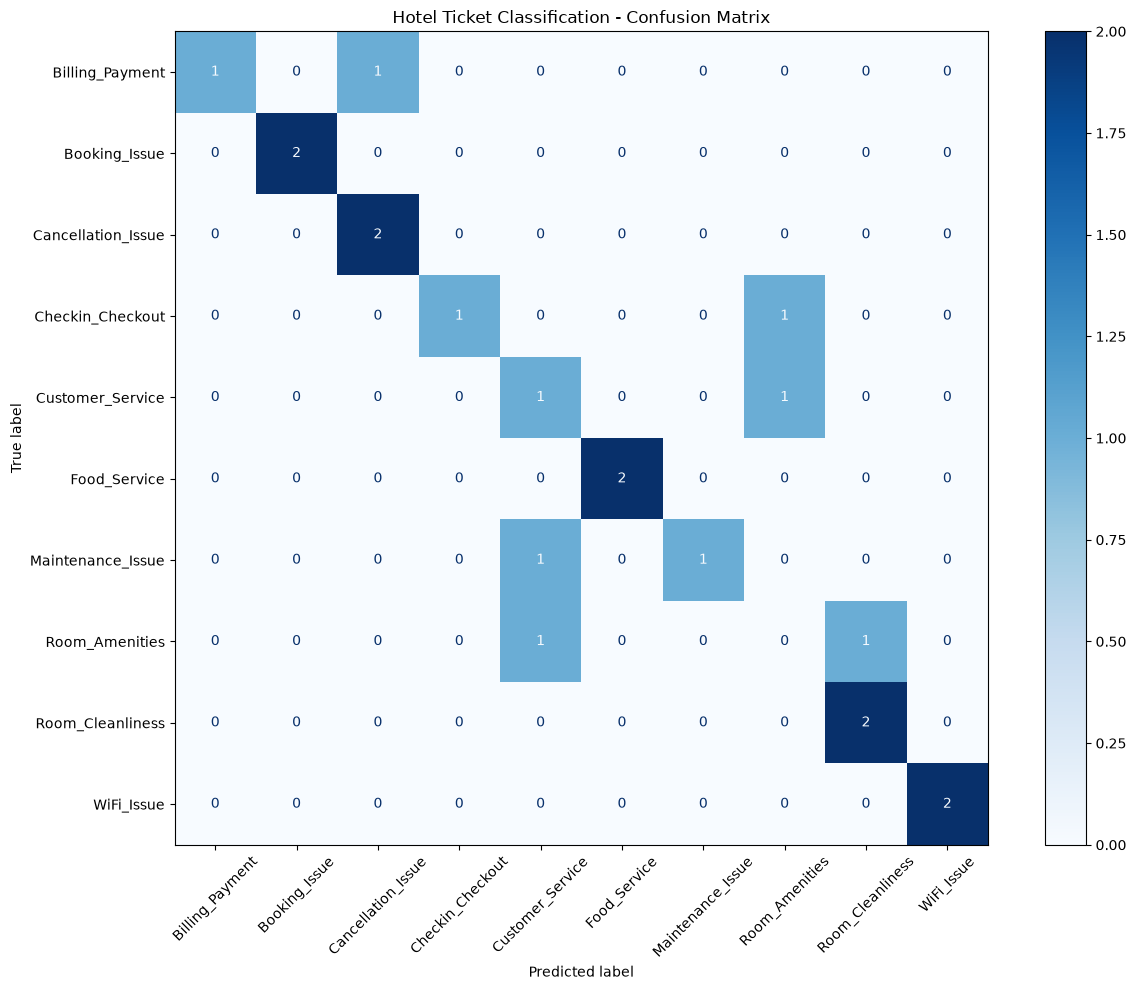

In [9]:
categories = sorted(df["expected_category"].unique())

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=categories
)

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=categories
)

fig, ax = plt.subplots(figsize=(13, 10))

display_plot.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Hotel Ticket Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [10]:
wrong_predictions = eval_df[
    eval_df["expected_category"] != eval_df["predicted_category"]
]

print("Incorrect predictions:", len(wrong_predictions))

display(
    wrong_predictions[
        ["id", "ticket", "expected_category", "predicted_category"]
    ]
)

Incorrect predictions: 6


,id,ticket,expected_category,predicted_category
28,H029,My room access card is not working.,Checkin_Checkout,Room_Amenities
48,H049,There are no clean towels in my room.,Room_Amenities,Room_Cleanliness
49,H050,The hair dryer is not available.,Room_Amenities,Customer_Service
58,H059,The room wall has water damage.,Maintenance_Issue,Customer_Service
88,H089,My refund amount is incorrect.,Billing_Payment,Cancellation_Issue
98,H099,I need information about hotel facilities.,Customer_Service,Room_Amenities


In [1]:
import importlib
import hotel_service

importlib.reload(hotel_service)

from hotel_service import analyze_ticket

print("Improved hotel classifier loaded!")

Improved hotel classifier loaded!


In [2]:
test_tickets = [
    "My room access card is not working.",
    "There are no clean towels in my room.",
    "The hair dryer is not available.",
    "The room wall has water damage.",
    "My refund amount is incorrect.",
    "I need information about hotel facilities."
]

for ticket in test_tickets:
    result = analyze_ticket(ticket)

    print("Ticket:", ticket)
    print("Predicted:", result.category)
    print("-" * 60)

Ticket: My room access card is not working.
Predicted: Checkin_Checkout
------------------------------------------------------------
Ticket: There are no clean towels in my room.
Predicted: Room_Amenities
------------------------------------------------------------
Ticket: The hair dryer is not available.
Predicted: Room_Amenities
------------------------------------------------------------
Ticket: The room wall has water damage.
Predicted: Maintenance_Issue
------------------------------------------------------------
Ticket: My refund amount is incorrect.
Predicted: Billing_Payment
------------------------------------------------------------
Ticket: I need information about hotel facilities.
Predicted: Room_Amenities
------------------------------------------------------------


In [4]:
import importlib
import hotel_service

importlib.reload(hotel_service)

from hotel_service import analyze_ticket

print("Updated classifier loaded!")

Updated classifier loaded!


In [7]:
import pandas as pd

dataset_path = r"E:\AI-Bootcamp\Module_05\a\dataset\hotel_support_tickets.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Total tickets:", len(df))

Dataset loaded successfully!
Total tickets: 100


In [8]:
eval_df = df[df["split"] == "eval"].copy()

print("Evaluation tickets:", len(eval_df))

display(eval_df.head())

Evaluation tickets: 20


,id,ticket,expected_category,split,required_terms
8,H009,The hotel website is not accepting my room boo...,Booking_Issue,eval,booking
9,H010,My reservation details are incorrect.,Booking_Issue,eval,booking
18,H019,Please confirm my room cancellation.,Cancellation_Issue,eval,cancel
19,H020,I need to know the cancellation policy.,Cancellation_Issue,eval,cancel
28,H029,My room access card is not working.,Checkin_Checkout,eval,check


In [9]:
import sys
import importlib

service_path = r"E:\AI-Bootcamp\Module_05\a"

if service_path not in sys.path:
    sys.path.insert(0, service_path)

import hotel_service

importlib.reload(hotel_service)

from hotel_service import analyze_ticket

print("Updated classifier loaded successfully!")

Updated classifier loaded successfully!


In [10]:
eval_df["updated_prediction"] = eval_df["ticket"].apply(
    lambda ticket: analyze_ticket(ticket).category
)

display(
    eval_df[
        ["id", "expected_category", "updated_prediction"]
    ]
)

,id,expected_category,updated_prediction
8,H009,Booking_Issue,Room_Amenities
9,H010,Booking_Issue,Booking_Issue
18,H019,Cancellation_Issue,Cancellation_Issue
19,H020,Cancellation_Issue,Cancellation_Issue
28,H029,Checkin_Checkout,Checkin_Checkout
29,H030,Checkin_Checkout,Checkin_Checkout
38,H039,Room_Cleanliness,Room_Cleanliness
39,H040,Room_Cleanliness,Room_Cleanliness
48,H049,Room_Amenities,Room_Amenities
49,H050,Room_Amenities,Room_Amenities


In [11]:
from sklearn.metrics import accuracy_score

updated_accuracy = accuracy_score(
    eval_df["expected_category"],
    eval_df["updated_prediction"]
)

print("Original accuracy: 70%")
print("Updated accuracy:", round(updated_accuracy * 100, 2), "%")

Original accuracy: 70%
Updated accuracy: 90.0 %


In [12]:
wrong_predictions = eval_df[
    eval_df["expected_category"] != eval_df["updated_prediction"]
]

print("Incorrect predictions:", len(wrong_predictions))

display(
    wrong_predictions[
        ["id", "ticket", "expected_category", "updated_prediction"]
    ]
)

Incorrect predictions: 2


,id,ticket,expected_category,updated_prediction
8,H009,The hotel website is not accepting my room boo...,Booking_Issue,Room_Amenities
98,H099,I need information about hotel facilities.,Customer_Service,Room_Amenities


In [13]:
import sys
import importlib

service_path = r"E:\AI-Bootcamp\Module_05\a"

if service_path not in sys.path:
    sys.path.insert(0, service_path)

import hotel_tfidf

importlib.reload(hotel_tfidf)

from hotel_tfidf import train_tfidf_model, predict_tfidf

print("TF-IDF classifier imported successfully!")

TF-IDF classifier imported successfully!


In [14]:
# Development data: 80 tickets
dev_df = df[df["split"] == "development"].copy()

# Evaluation data: 20 tickets
eval_df = df[df["split"] == "eval"].copy()

print("Development tickets:", len(dev_df))
print("Evaluation tickets:", len(eval_df))

Development tickets: 80
Evaluation tickets: 20


In [15]:
vectorizer, ticket_matrix, labels = train_tfidf_model(dev_df)

print("TF-IDF model prepared successfully!")
print("Development matrix shape:", ticket_matrix.shape)

TF-IDF model prepared successfully!
Development matrix shape: (80, 367)


In [16]:
predictions = []
similarity_scores = []

for ticket in eval_df["ticket"]:

    category, score = predict_tfidf(
        ticket,
        vectorizer,
        ticket_matrix,
        labels
    )

    predictions.append(category)
    similarity_scores.append(score)


eval_df["tfidf_prediction"] = predictions
eval_df["similarity_score"] = similarity_scores

display(
    eval_df[
        [
            "id",
            "ticket",
            "expected_category",
            "tfidf_prediction",
            "similarity_score"
        ]
    ]
)

,id,ticket,expected_category,tfidf_prediction,similarity_score
8,H009,The hotel website is not accepting my room boo...,Booking_Issue,Booking_Issue,0.4928
9,H010,My reservation details are incorrect.,Booking_Issue,Booking_Issue,0.3671
18,H019,Please confirm my room cancellation.,Cancellation_Issue,Cancellation_Issue,0.3846
19,H020,I need to know the cancellation policy.,Cancellation_Issue,Cancellation_Issue,0.5012
28,H029,My room access card is not working.,Checkin_Checkout,Billing_Payment,0.2272
29,H030,The reception staff is not helping with check-in.,Checkin_Checkout,Customer_Service,0.3034
38,H039,My room has not received daily cleaning.,Room_Cleanliness,Booking_Issue,0.4975
39,H040,The bathroom floor is dirty.,Room_Cleanliness,Room_Cleanliness,0.3022
48,H049,There are no clean towels in my room.,Room_Amenities,Room_Cleanliness,0.4244
49,H050,The hair dryer is not available.,Room_Amenities,Booking_Issue,0.0000


In [17]:
from sklearn.metrics import accuracy_score

tfidf_accuracy = accuracy_score(
    eval_df["expected_category"],
    eval_df["tfidf_prediction"]
)

print("TF-IDF Accuracy:", round(tfidf_accuracy * 100, 2), "%")

TF-IDF Accuracy: 60.0 %


In [18]:
# Keyword classifier predictions
from hotel_service import analyze_ticket

eval_df["keyword_prediction"] = eval_df["ticket"].apply(
    lambda ticket: analyze_ticket(ticket).category
)

keyword_accuracy = accuracy_score(
    eval_df["expected_category"],
    eval_df["keyword_prediction"]
)

comparison = pd.DataFrame({
    "Classifier": [
        "Keyword-Based Classifier",
        "TF-IDF + Cosine Similarity"
    ],
    "Accuracy": [
        round(keyword_accuracy * 100, 2),
        round(tfidf_accuracy * 100, 2)
    ]
})

display(comparison)

,Classifier,Accuracy
0,Keyword-Based Classifier,90.0
1,TF-IDF + Cosine Similarity,60.0


In [19]:
comparison = pd.DataFrame({
    "Classifier": [
        "Keyword-Based Classifier",
        "TF-IDF + Cosine Similarity"
    ],
    "Correct_Predictions": [18, 12],
    "Incorrect_Predictions": [2, 8],
    "Accuracy": [90.0, 60.0]
})

comparison.to_csv(
    "hotel_classifier_comparison.csv",
    index=False
)

display(comparison)

print("Comparison results saved successfully!")

,Classifier,Correct_Predictions,Incorrect_Predictions,Accuracy
0,Keyword-Based Classifier,18,2,90.0
1,TF-IDF + Cosine Similarity,12,8,60.0


Comparison results saved successfully!
